# Punto 1A · Modelo de difusión (DDPM) entrenado con **MNIST**

**Universidad Autónoma de Occidente** · Inteligencia Artificial Generativa · Ingeniería de Datos e IA
Profesores: Jesús Alfonso López – José Luis Paniagua

En este notebook partimos del código de ejemplo de la clase (DDPM sobre Fashion MNIST) y hacemos tres cosas:

1. **Cambiamos el conjunto de datos** por el MNIST tradicional (dígitos escritos a mano, 28×28, escala de grises).
2. **Entrenamos** el mismo modelo de difusión tipo UNet para que aprenda a quitar ruido de imágenes de dígitos.
3. **Evaluamos la calidad** de las imágenes generadas con métricas cuantitativas: FID, KID, *Inception/Classifier Score*, confianza de un clasificador y cobertura de clases.

Como MNIST tiene exactamente la misma forma que Fashion MNIST (28×28×1), la arquitectura del profe funciona sin cambios: lo único que cambia es la fuente de datos. Eso nos permite comparar de forma limpia.

> ⚙️ Antes de correr: **Entorno de ejecución → Cambiar tipo de entorno → GPU (T4)**.

## 0. Configuración del entorno
Mantenemos la misma configuración del notebook original para garantizar compatibilidad entre Python, TensorFlow y Keras (en Colab se usa *Keras legacy* `tf_keras`, que permite mezclar operaciones de TensorFlow dentro del modelo funcional).

In [11]:
import sys, os
assert sys.version_info >= (3, 7)

IS_COLAB = "google.colab" in sys.modules
if IS_COLAB:
    # Debe ir ANTES de importar tensorflow: fuerza Keras 2 (tf_keras)
    os.environ["TF_USE_LEGACY_KERAS"] = "1"
    import tf_keras

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from packaging import version
from scipy import linalg

assert version.parse(tf.__version__) >= version.parse("2.8.0")
print("TensorFlow:", tf.__version__)

if not tf.config.list_physical_devices("GPU"):
    print("⚠️ No se detectó GPU. El entrenamiento y sobre todo la generación serán MUY lentos.")
else:
    print("GPU detectada:", tf.config.list_physical_devices("GPU")[0])

TensorFlow: 2.20.0
⚠️ No se detectó GPU. El entrenamiento y sobre todo la generación serán MUY lentos.


## 1. Carga de MNIST
Aquí está el cambio principal respecto al notebook original: `fashion_mnist` → `mnist`. Normalizamos a [0, 1] (luego `prepare_batch` lo lleva a [–1, 1]) y separamos 5.000 imágenes para validación, igual que en el ejemplo.

In [12]:
mnist = tf.keras.datasets.mnist.load_data()          # <-- ÚNICO cambio de datos
(X_train_full, y_train_full), (X_test, y_test) = mnist
X_train_full = X_train_full.astype(np.float32) / 255
X_test = X_test.astype(np.float32) / 255
X_train, X_valid = X_train_full[:-5000], X_train_full[-5000:]
y_train, y_valid = y_train_full[:-5000], y_train_full[-5000:]

print("Entrenamiento:", X_train.shape, "| Validación:", X_valid.shape, "| Prueba:", X_test.shape)

Entrenamiento: (55000, 28, 28) | Validación: (5000, 28, 28) | Prueba: (10000, 28, 28)


Algunos dígitos reales de MNIST:


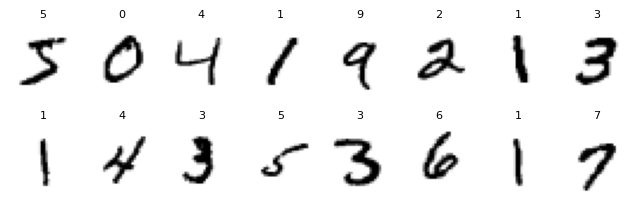

In [13]:
def plot_multiple_images(images, n_cols=None, titles=None):
    # Muestra una cuadrícula de imágenes. Acepta (N, H, W) o (N, H, W, 1)
    images = np.asarray(images)
    n_cols = n_cols or len(images)
    n_rows = (len(images) - 1) // n_cols + 1
    if images.shape[-1] == 1:
        images = images.squeeze(axis=-1)
    plt.figure(figsize=(n_cols, n_rows * (1.2 if titles is not None else 1)))
    for index, image in enumerate(images):
        plt.subplot(n_rows, n_cols, index + 1)
        plt.imshow(image, cmap="binary")
        if titles is not None:
            plt.title(titles[index], fontsize=8)
        plt.axis("off")

print("Algunos dígitos reales de MNIST:")
plot_multiple_images(X_train[:16], 8, titles=[str(y) for y in y_train[:16]])
plt.show()

## 2. Proceso de difusión directo (*forward*)

En cada paso $t$ se añade ruido gaussiano con varianza $\beta_t$. Usamos la programación coseno del artículo *Improved DDPM* con $T = 4000$, exactamente como en el ejemplo. Gracias a la ecuación (4) del artículo DDPM podemos saltar directamente de la imagen limpia $x_0$ a la imagen ruidosa $x_t$:

$$x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\varepsilon,\qquad \varepsilon\sim\mathcal N(0, I)$$

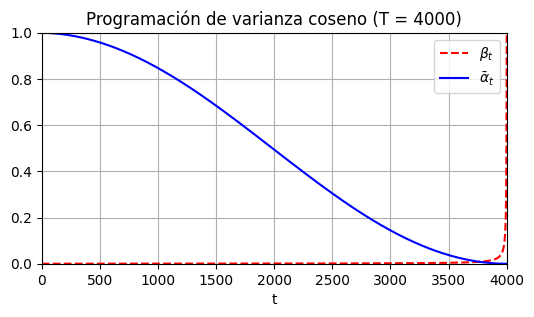

In [14]:
def variance_schedule(T, s=0.008, max_beta=0.999):
    # Programación coseno (Improved DDPM): ᾱ_t baja suavemente de 1 a 0
    t = np.arange(T + 1)
    f = np.cos((t / T + s) / (1 + s) * np.pi / 2) ** 2
    alpha = np.clip(f[1:] / f[:-1], 1 - max_beta, 1)
    alpha = np.append(1, alpha).astype(np.float32)  # α₀ = 1
    beta = 1 - alpha
    alpha_cumprod = np.cumprod(alpha)
    return alpha, alpha_cumprod, beta  # αₜ, ᾱₜ, βₜ para t = 0..T

np.random.seed(42)
T = 4000
alpha, alpha_cumprod, beta = variance_schedule(T)

plt.figure(figsize=(6, 3))
plt.plot(beta, "r--", label=r"$\beta_t$")
plt.plot(alpha_cumprod, "b", label=r"$\bar{\alpha}_t$")
plt.axis([0, T, 0, 1]); plt.grid(True); plt.xlabel("t"); plt.legend()
plt.title("Programación de varianza coseno (T = 4000)")
plt.show()

In [15]:
def prepare_batch(X):
    # Toma un lote de imágenes limpias y devuelve (entradas, objetivo):
    #   entradas = imagen ruidosa x_t y el paso t (aleatorio entre 1 y T)
    #   objetivo = el ruido ε que se añadió (es lo que la red debe predecir)
    X = tf.cast(X[..., tf.newaxis], tf.float32) * 2 - 1  # escala a [-1, 1]
    X_shape = tf.shape(X)
    t = tf.random.uniform([X_shape[0]], minval=1, maxval=T + 1, dtype=tf.int32)
    alpha_cm = tf.gather(alpha_cumprod, t)
    alpha_cm = tf.reshape(alpha_cm, [X_shape[0]] + [1] * (len(X.shape) - 1))
    noise = tf.random.normal(X_shape)
    return {
        "X_noisy": alpha_cm ** 0.5 * X + (1 - alpha_cm) ** 0.5 * noise,
        "time": t,
    }, noise

def prepare_dataset(X, batch_size=32, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices(X)
    if shuffle:
        ds = ds.shuffle(10_000)
    return ds.batch(batch_size).map(prepare_batch, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

tf.random.set_seed(43)
BATCH_SIZE = 32
train_set = prepare_dataset(X_train, batch_size=BATCH_SIZE, shuffle=True)
valid_set = prepare_dataset(X_valid, batch_size=BATCH_SIZE)

Comprobación rápida: tomamos un lote, miramos las imágenes ruidosas, el ruido que hay que predecir y reconstruimos la original restando el ruido escalado. Si la reconstrucción se ve perfecta, el *pipeline* de datos está bien.

Imágenes originales reconstruidas


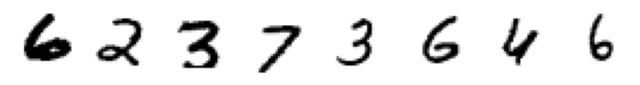

Pasos de tiempo: [3405  312 3441 1991 2443 1657 3308 1151]
Imágenes ruidosas


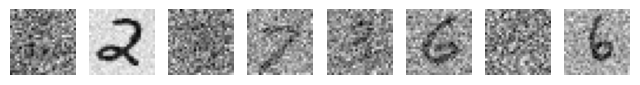

Ruido a predecir


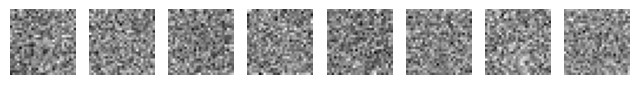

In [16]:
def subtract_noise(X_noisy, time, noise):
    X_shape = tf.shape(X_noisy)
    alpha_cm = tf.gather(alpha_cumprod, time)
    alpha_cm = tf.reshape(alpha_cm, [X_shape[0]] + [1] * (len(X_noisy.shape) - 1))
    return (X_noisy - (1 - alpha_cm) ** 0.5 * noise) / alpha_cm ** 0.5

X_dict, Y_noise = list(train_set.take(1))[0]
X_original = subtract_noise(X_dict["X_noisy"], X_dict["time"], Y_noise)

print("Imágenes originales reconstruidas"); plot_multiple_images(X_original[:8].numpy()); plt.show()
print("Pasos de tiempo:", X_dict["time"].numpy()[:8])
print("Imágenes ruidosas"); plot_multiple_images(X_dict["X_noisy"][:8].numpy()); plt.show()
print("Ruido a predecir"); plot_multiple_images(Y_noise[:8].numpy()); plt.show()

Y para ver el proceso directo de forma más intuitiva, tomamos un mismo dígito y lo vamos ensuciando a distintos $t$:

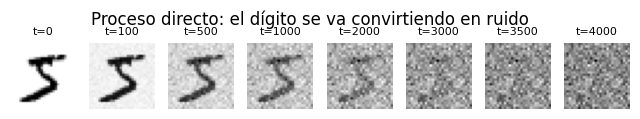

In [17]:
x0 = X_train[0][np.newaxis, ..., np.newaxis] * 2 - 1
steps_to_show = [int(T * f) for f in (0, 0.025, 0.125, 0.25, 0.5, 0.75, 0.875, 1.0)]
eps = np.random.randn(*x0.shape).astype(np.float32)
noisy = [np.sqrt(alpha_cumprod[t]) * x0[0] + np.sqrt(1 - alpha_cumprod[t]) * eps[0] for t in steps_to_show]
plot_multiple_images(np.array(noisy), 8, titles=[f"t={t}" for t in steps_to_show])
plt.suptitle("Proceso directo: el dígito se va convirtiendo en ruido", y=1.05)
plt.show()

## 3. El modelo: UNet con codificación temporal

Usamos **la misma arquitectura del ejemplo**. La red recibe la imagen ruidosa y el paso $t$; el tiempo se codifica con senos y cosenos (como en *Attention is all you need*), pasa por una capa `Dense` y se suma a cada píxel en cada bloque. La UNet baja la resolución 32→16→8→4 y la vuelve a subir, con conexiones de salto entre ambas mitades.

No hace falta tocarla porque MNIST también es 28×28×1 (la red rellena a 34×34 con `ZeroPadding2D`, trabaja en 32×32 y al final recorta a 28×28).

In [18]:
embed_size = 64

class TimeEncoding(tf.keras.layers.Layer):
    # Codificación sinusoidal del paso t (tabla precalculada de T+1 filas)
    def __init__(self, T, embed_size, dtype=tf.float32, **kwargs):
        super().__init__(dtype=dtype, **kwargs)
        assert embed_size % 2 == 0, "embed_size debe ser par"
        p, i = np.meshgrid(np.arange(T + 1), 2 * np.arange(embed_size // 2))
        t_emb = np.empty((T + 1, embed_size))
        t_emb[:, ::2] = np.sin(p / 10_000 ** (i / embed_size)).T
        t_emb[:, 1::2] = np.cos(p / 10_000 ** (i / embed_size)).T
        self.time_encodings = tf.constant(t_emb.astype(self.dtype))

    def call(self, inputs):
        return tf.gather(self.time_encodings, inputs)


def build_diffusion_model():
    X_noisy = tf.keras.layers.Input(shape=[28, 28, 1], name="X_noisy")
    time_input = tf.keras.layers.Input(shape=[], dtype=tf.int32, name="time")
    time_enc = TimeEncoding(T, embed_size)(time_input)

    dim = 16
    Z = tf.keras.layers.ZeroPadding2D((3, 3))(X_noisy)       # 28 -> 34
    Z = tf.keras.layers.Conv2D(dim, 3)(Z)                     # 34 -> 32
    Z = tf.keras.layers.BatchNormalization()(Z)
    Z = tf.keras.layers.Activation("relu")(Z)

    time = tf.keras.layers.Dense(dim)(time_enc)               # adapta la codificación temporal
    Z = time[:, tf.newaxis, tf.newaxis, :] + Z                # suma el tiempo a cada píxel

    skip = Z
    cross_skips = []  # conexiones de salto entre la parte de bajada y la de subida

    # ----- Codificador (bajada): 32 -> 16 -> 8 -> 4 -----
    for dim in (32, 64, 128):
        Z = tf.keras.layers.Activation("relu")(Z)
        Z = tf.keras.layers.SeparableConv2D(dim, 3, padding="same")(Z)
        Z = tf.keras.layers.BatchNormalization()(Z)
        Z = tf.keras.layers.Activation("relu")(Z)
        Z = tf.keras.layers.SeparableConv2D(dim, 3, padding="same")(Z)
        Z = tf.keras.layers.BatchNormalization()(Z)

        cross_skips.append(Z)
        Z = tf.keras.layers.MaxPooling2D(3, strides=2, padding="same")(Z)
        skip_link = tf.keras.layers.Conv2D(dim, 1, strides=2, padding="same")(skip)
        Z = tf.keras.layers.add([Z, skip_link])               # conexión residual

        time = tf.keras.layers.Dense(dim)(time_enc)
        Z = time[:, tf.newaxis, tf.newaxis, :] + Z
        skip = Z

    # ----- Decodificador (subida): 4 -> 8 -> 16 -> 32 -----
    for dim in (64, 32, 16):
        Z = tf.keras.layers.Activation("relu")(Z)
        Z = tf.keras.layers.Conv2DTranspose(dim, 3, padding="same")(Z)
        Z = tf.keras.layers.BatchNormalization()(Z)
        Z = tf.keras.layers.Activation("relu")(Z)
        Z = tf.keras.layers.Conv2DTranspose(dim, 3, padding="same")(Z)
        Z = tf.keras.layers.BatchNormalization()(Z)

        Z = tf.keras.layers.UpSampling2D(2)(Z)
        skip_link = tf.keras.layers.UpSampling2D(2)(skip)
        skip_link = tf.keras.layers.Conv2D(dim, 1, padding="same")(skip_link)
        Z = tf.keras.layers.add([Z, skip_link])

        time = tf.keras.layers.Dense(dim)(time_enc)
        Z = time[:, tf.newaxis, tf.newaxis, :] + Z
        Z = tf.keras.layers.concatenate([Z, cross_skips.pop()], axis=-1)  # salto cruzado UNet
        skip = Z

    outputs = tf.keras.layers.Conv2D(1, 3, padding="same")(Z)[:, 2:-2, 2:-2]  # recorta 32 -> 28
    return tf.keras.Model(inputs=[X_noisy, time_input], outputs=[outputs])

tf.random.set_seed(42)
model = build_diffusion_model()
print(f"Parámetros del modelo: {model.count_params():,}")

Parámetros del modelo: 280,369


## 4. Entrenamiento
La red aprende a predecir el ruido $\varepsilon$ a partir de $(x_t, t)$. Usamos pérdida Huber y Nadam como en el ejemplo. Subimos las épocas a 20 porque MNIST se beneficia de algo más de entrenamiento (cada época tarda ~45 s en una T4); guardamos solo los mejores pesos según la pérdida de validación.

In [19]:
EPOCHS = 20

model.compile(loss=tf.keras.losses.Huber(), optimizer=tf.keras.optimizers.Nadam())

checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(
    "mnist_diffusion_best.weights.h5", save_best_only=True, save_weights_only=True)
reduce_lr_cb = tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=3, verbose=1)

t0 = time.time()
history = model.fit(train_set, validation_data=valid_set, epochs=EPOCHS,
                    callbacks=[checkpoint_cb, reduce_lr_cb])
print(f"Tiempo de entrenamiento: {(time.time() - t0) / 60:.1f} min")

model.load_weights("mnist_diffusion_best.weights.h5")   # nos quedamos con la mejor época

Epoch 1/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 142s 68ms/step - loss: 0.0959 - val_loss: 0.0564 - learning_rate: 0.0010
Epoch 2/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 136s 64ms/step - loss: 0.0444 - val_loss: 0.0375 - learning_rate: 0.0010
Epoch 3/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 109s 63ms/step - loss: 0.0346 - val_loss: 0.0318 - learning_rate: 0.0010
Epoch 4/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 109s 63ms/step - loss: 0.0310 - val_loss: 0.0328 - learning_rate: 0.0010
Epoch 5/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 108s 63ms/step - loss: 0.0289 - val_loss: 0.0287 - learning_rate: 0.0010
Epoch 6/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 109s 63ms/step - loss: 0.0274 - val_loss: 0.0293 - learning_rate: 0.0010
Epoch 7/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 110s 64ms/step - loss: 0.0263 - val_loss: 0.0286 - learning_rate: 0.0010
Epoch 8/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 142s 64ms/step - loss: 0.0255 - val_loss: 0.0278 - learning_rate: 0.0010
Epoch 9/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 142s 64ms/step - loss: 0.0250 - val_lo

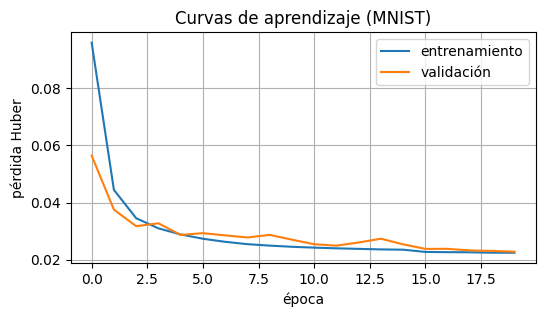

In [20]:
plt.figure(figsize=(6, 3))
plt.plot(history.history["loss"], label="entrenamiento")
plt.plot(history.history["val_loss"], label="validación")
plt.xlabel("época"); plt.ylabel("pérdida Huber"); plt.grid(True); plt.legend()
plt.title("Curvas de aprendizaje (MNIST)")
plt.show()

## 5. Generación de imágenes (proceso inverso)

Partimos de ruido puro $x_T\sim\mathcal N(0,I)$ y aplicamos el paso 4 del Algoritmo 2 del artículo DDPM, desde $t=T$ hasta $t=1$:

$$x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\left(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\varepsilon_\theta(x_t,t)\right) + \sqrt{\beta_t}\,z$$

**Mejora respecto al ejemplo:** el paso de *denoising* está envuelto en `@tf.function`, así TensorFlow lo compila a grafo una sola vez y las 4.000 llamadas a la red son mucho más rápidas. Eso es lo que nos permite generar suficientes imágenes (1.000) para calcular las métricas de forma confiable.

lote 1 | t =  500 
32 imágenes generadas en 71.5 s


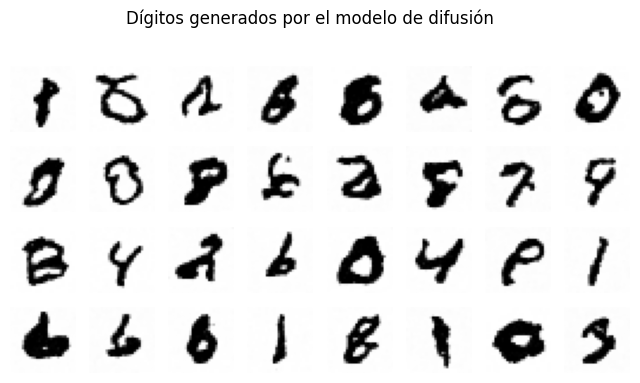

In [21]:
alpha_tf = tf.constant(alpha)
beta_tf = tf.constant(beta)
alpha_cumprod_tf = tf.constant(alpha_cumprod)

@tf.function
def denoise_step(X, t):
    # Un paso del proceso inverso DDPM: x_t -> x_{t-1}
    batch = tf.shape(X)[0]
    t_vec = tf.fill([batch], t)
    eps_pred = model({"X_noisy": X, "time": t_vec}, training=False)
    a_t = tf.gather(alpha_tf, t)
    b_t = tf.gather(beta_tf, t)
    ab_t = tf.gather(alpha_cumprod_tf, t)
    mean = (X - b_t / tf.sqrt(1 - ab_t) * eps_pred) / tf.sqrt(a_t)
    z = tf.random.normal(tf.shape(X)) * tf.cast(t > 1, tf.float32)  # sin ruido en el último paso
    return mean + tf.sqrt(b_t) * z

def generate(n_images=32, batch_size=500, snapshot_steps=None, verbose=True):
    # Genera n_images; si se pasa snapshot_steps guarda x_t en esos pasos (para visualizar)
    outputs, snapshots = [], {}
    for start in range(0, n_images, batch_size):
        bs = min(batch_size, n_images - start)
        X = tf.random.normal([bs, 28, 28, 1])
        for t in range(T, 0, -1):
            X = denoise_step(X, tf.constant(t, tf.int32))
            if snapshot_steps is not None and start == 0 and (t - 1) in snapshot_steps:
                snapshots[t - 1] = X.numpy()
            if verbose and t % max(T // 8, 1) == 0:
                print(f"\rlote {start // batch_size + 1} | t = {t:4d}", end=" ")
        outputs.append(tf.clip_by_value(X, -1, 1).numpy())
    if verbose:
        print()
    X_gen = np.concatenate(outputs)
    return (X_gen, snapshots) if snapshot_steps is not None else X_gen

tf.random.set_seed(42)
t0 = time.time()
snap_steps = [T - 1] + [int(T * f) for f in (0.75, 0.5, 0.375, 0.25, 0.15, 0.075, 0.025, 0.0075)] + [0]
X_gen_demo, snaps = generate(32, batch_size=32, snapshot_steps=snap_steps)
print(f"32 imágenes generadas en {time.time() - t0:.1f} s")

plot_multiple_images(X_gen_demo, 8)
plt.suptitle("Dígitos generados por el modelo de difusión", y=1.02)
plt.show()

### Visualización del proceso inverso
Cada fila es una imagen distinta; de izquierda a derecha vemos cómo el ruido se va organizando en un dígito. Nótese que la forma global aparece relativamente tarde (por la programación coseno, la mayor parte de la estructura se decide en la segunda mitad del proceso).

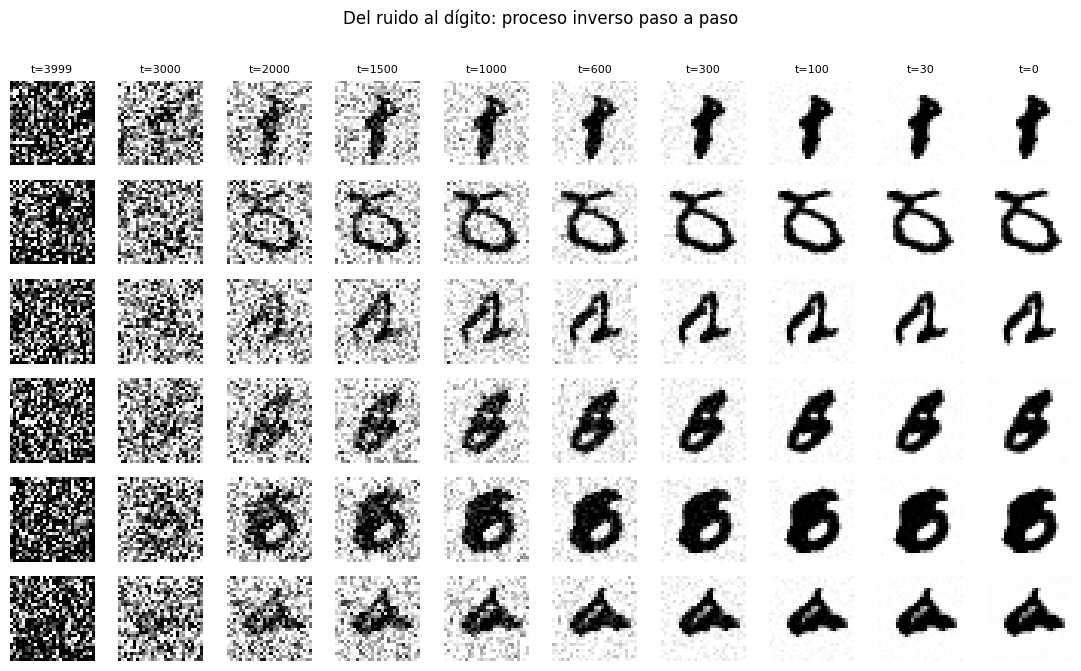

In [22]:
order = sorted(snaps.keys(), reverse=True)
n_show = 6
fig, axes = plt.subplots(n_show, len(order), figsize=(len(order) * 1.1, n_show * 1.1))
for r in range(n_show):
    for c, t in enumerate(order):
        axes[r, c].imshow(np.clip(snaps[t][r, ..., 0], -1, 1), cmap="binary")
        axes[r, c].axis("off")
        if r == 0:
            axes[r, c].set_title(f"t={t}", fontsize=8)
plt.suptitle("Del ruido al dígito: proceso inverso paso a paso", y=1.01)
plt.tight_layout(); plt.show()

## 6. Evaluación cuantitativa de la calidad

Mirar las imágenes no es suficiente; necesitamos números. Las métricas estándar para modelos generativos de imágenes son:

| Métrica | Qué mide | Mejor si… |
|---|---|---|
| **FID** (*Fréchet Inception Distance*) | Distancia entre la distribución de características de imágenes reales y generadas (media y covarianza). Captura calidad **y** diversidad. | ↓ más bajo |
| **KID** (*Kernel Inception Distance*) | Parecido al FID pero con un estimador insesgado (MMD con kernel polinomial). Más confiable con pocas muestras. | ↓ más bajo |
| **IS / Classifier Score** | $\exp(\mathbb E_x[KL(p(y\mid x)\,\|\,p(y))])$: alto si cada imagen se clasifica con seguridad (nitidez) y las clases están balanceadas (diversidad). Máximo teórico = 10 en MNIST. | ↑ más alto |
| **Confianza media** | Probabilidad máxima promedio del clasificador: ¿la imagen parece claramente un dígito? | ↑ más alto |
| **Cobertura de clases** | Histograma de clases predichas y su entropía: detecta *mode collapse* (que el modelo solo genere algunos dígitos). | entropía ≈ ln 10 = 2.30 |

**Detalle importante:** el FID “oficial” usa InceptionV3 entrenada en ImageNet, pero para dígitos en escala de grises de 28×28 eso no tiene mucho sentido. La práctica habitual en MNIST es usar como extractor de características **un clasificador entrenado en MNIST** (las activaciones de su penúltima capa). Eso es lo que hacemos aquí. Por eso los valores no son comparables con FID publicados en ImageNet/CIFAR, pero sí entre modelos evaluados con el mismo extractor, y los acompañamos de **líneas base** (real vs real y ruido vs real) para interpretarlos.

### 6.1 Clasificador de referencia para MNIST

In [23]:
def build_classifier():
    inp = tf.keras.layers.Input(shape=[28, 28, 1])
    x = tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu")(inp)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = tf.keras.layers.MaxPooling2D()(x)
    x = tf.keras.layers.Dropout(0.25)(x)
    x = tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = tf.keras.layers.MaxPooling2D()(x)
    x = tf.keras.layers.Flatten()(x)
    x = tf.keras.layers.Dense(128, activation="relu", name="features")(x)   # <- características para FID/KID
    x = tf.keras.layers.Dropout(0.5)(x)
    out = tf.keras.layers.Dense(10, activation="softmax")(x)
    return tf.keras.Model(inp, out)

# El clasificador recibe imágenes en [-1, 1], el mismo rango que produce el generador
to_pm1 = lambda X: (X[..., np.newaxis] * 2 - 1).astype(np.float32)

clf = build_classifier()
clf.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
clf.fit(to_pm1(X_train), y_train, validation_data=(to_pm1(X_valid), y_valid),
        epochs=5, batch_size=128, verbose=2)
_, test_acc = clf.evaluate(to_pm1(X_test), y_test, verbose=0)
print(f"Exactitud del clasificador en prueba: {test_acc:.4f}")

feature_extractor = tf.keras.Model(clf.input, clf.get_layer("features").output)

Epoch 1/5
430/430 - 39s - 91ms/step - accuracy: 0.7581 - loss: 0.6970 - val_accuracy: 0.9780 - val_loss: 0.1283
Epoch 2/5
430/430 - 38s - 89ms/step - accuracy: 0.8968 - loss: 0.2917 - val_accuracy: 0.9860 - val_loss: 0.0527
Epoch 3/5
430/430 - 36s - 84ms/step - accuracy: 0.9143 - loss: 0.2437 - val_accuracy: 0.9880 - val_loss: 0.0411
Epoch 4/5
430/430 - 37s - 86ms/step - accuracy: 0.9281 - loss: 0.2015 - val_accuracy: 0.9908 - val_loss: 0.0375
Epoch 5/5
430/430 - 37s - 86ms/step - accuracy: 0.9396 - loss: 0.1731 - val_accuracy: 0.9918 - val_loss: 0.0316
Exactitud del clasificador en prueba: 0.9902


### 6.2 Funciones de las métricas

In [24]:
def get_feats_probs(X, batch_size=500):
    feats = feature_extractor.predict(X, batch_size=batch_size, verbose=0).astype(np.float64)
    probs = clf.predict(X, batch_size=batch_size, verbose=0).astype(np.float64)
    return feats, probs

def fid(f1, f2):
    # FID = ||μ1-μ2||² + Tr(Σ1 + Σ2 - 2(Σ1Σ2)^½)
    mu1, mu2 = f1.mean(0), f2.mean(0)
    s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    covmean = linalg.sqrtm(s1.dot(s2))
    if isinstance(covmean, tuple):          # compatibilidad entre versiones de SciPy
        covmean = covmean[0]
    if not np.isfinite(covmean).all():      # estabilización numérica si la matriz es casi singular
        off = np.eye(s1.shape[0]) * 1e-6
        covmean = linalg.sqrtm((s1 + off).dot(s2 + off))
        covmean = covmean[0] if isinstance(covmean, tuple) else covmean
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1 + s2 - 2 * covmean))

def kid(f1, f2, n_subsets=50, subset_size=500, seed=0):
    # KID: MMD² insesgado con kernel polinomial k(x,y) = (x·y/d + 1)³; promedio sobre subconjuntos
    rng = np.random.default_rng(seed)
    d = f1.shape[1]
    m = min(subset_size, len(f1), len(f2))
    vals = []
    for _ in range(n_subsets):
        x = f1[rng.choice(len(f1), m, replace=False)]
        y = f2[rng.choice(len(f2), m, replace=False)]
        kxx = (x @ x.T / d + 1) ** 3
        kyy = (y @ y.T / d + 1) ** 3
        kxy = (x @ y.T / d + 1) ** 3
        mmd = ((kxx.sum() - np.trace(kxx)) / (m * (m - 1))
               + (kyy.sum() - np.trace(kyy)) / (m * (m - 1))
               - 2 * kxy.mean())
        vals.append(mmd)
    return float(np.mean(vals)), float(np.std(vals))

def inception_score(probs, splits=10):
    # IS = exp(E_x KL(p(y|x) || p(y))), calculado en 'splits' particiones
    scores = []
    for part in np.array_split(probs, splits):
        py = part.mean(0, keepdims=True)
        kl = (part * (np.log(part + 1e-12) - np.log(py + 1e-12))).sum(1)
        scores.append(np.exp(kl.mean()))
    return float(np.mean(scores)), float(np.std(scores))

def class_stats(probs):
    pred = probs.argmax(1)
    hist = np.bincount(pred, minlength=10) / len(pred)
    entropy = float(-(hist * np.log(hist + 1e-12)).sum())
    return pred, hist, entropy, float(probs.max(1).mean()), float((probs.max(1) > 0.9).mean())

### 6.3 Generar un conjunto grande de imágenes para evaluar
Con 1.000 imágenes las métricas ya son estables (el KID es insesgado; el FID tiene un pequeño sesgo con pocas muestras, por eso comparamos siempre con el mismo N). En una T4 esto tarda unos minutos.

In [25]:
N_EVAL = 1000

tf.random.set_seed(123)
t0 = time.time()
X_gen = generate(N_EVAL, batch_size=500)
print(f"{N_EVAL} imágenes generadas en {(time.time() - t0) / 60:.1f} min")

rng = np.random.default_rng(0)
X_real_test = to_pm1(X_test[rng.choice(len(X_test), N_EVAL, replace=False)])
X_real_train = to_pm1(X_train[rng.choice(len(X_train), N_EVAL, replace=False)])
X_noise = np.clip(np.random.randn(N_EVAL, 28, 28, 1), -1, 1).astype(np.float32)

f_test, p_test = get_feats_probs(X_real_test)
f_train, p_train = get_feats_probs(X_real_train)
f_gen, p_gen = get_feats_probs(X_gen)
f_noise, p_noise = get_feats_probs(X_noise)

lote 2 | t =  500 
1000 imágenes generadas en 29.6 min


In [26]:
rows = []
for name, f, p in [("Real (train) — línea base ideal", f_train, p_train),
                   ("Generadas por difusión", f_gen, p_gen),
                   ("Ruido gaussiano — peor caso", f_noise, p_noise)]:
    k_mean, k_std = kid(f, f_test)
    is_mean, is_std = inception_score(p)
    _, _, ent, conf, frac = class_stats(p)
    rows.append({"Conjunto": name,
                 "FID ↓": fid(f, f_test),
                 "KID×1000 ↓": k_mean * 1000,
                 "Classifier/Inception Score ↑": is_mean,
                 "Confianza media ↑": conf,
                 "% con conf>0.9 ↑": 100 * frac,
                 "Entropía de clases (máx 2.30)": ent})

results = pd.DataFrame(rows).set_index("Conjunto")
pd.options.display.float_format = "{:.3f}".format
print("Todas las distancias se calculan contra", N_EVAL, "imágenes reales del conjunto de PRUEBA")
display(results)

Todas las distancias se calculan contra 1000 imágenes reales del conjunto de PRUEBA


,FID ↓,KID×1000 ↓,Classifier/Inception Score ↑,Confianza media ↑,% con conf>0.9 ↑,Entropía de clases (máx 2.30)
Conjunto,,,,,,
Real (train) — línea base ideal,15.255,7313.325,9.388,0.993,98.000,2.298
Generadas por difusión,287.919,493184.632,6.627,0.897,72.000,2.193
Ruido gaussiano — peor caso,2093.443,1208515.755,1.000,1.000,100.000,-0.000


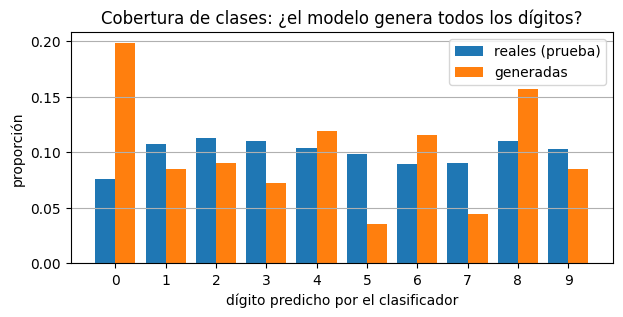

In [27]:
pred_gen, hist_gen, _, _, _ = class_stats(p_gen)
_, hist_real, _, _, _ = class_stats(p_test)

plt.figure(figsize=(7, 3))
w = 0.4
plt.bar(np.arange(10) - w / 2, hist_real, w, label="reales (prueba)")
plt.bar(np.arange(10) + w / 2, hist_gen, w, label="generadas")
plt.xticks(range(10)); plt.xlabel("dígito predicho por el clasificador"); plt.ylabel("proporción")
plt.title("Cobertura de clases: ¿el modelo genera todos los dígitos?")
plt.legend(); plt.grid(axis="y"); plt.show()

### 6.4 Inspección cualitativa guiada por las métricas
Ordenamos las imágenes generadas por la confianza del clasificador: arriba las más “legibles”, abajo las más ambiguas. Esto ayuda a entender qué tipo de errores comete el modelo.

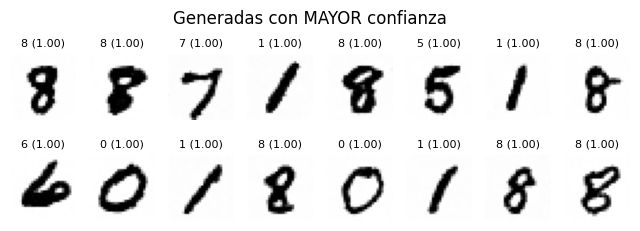

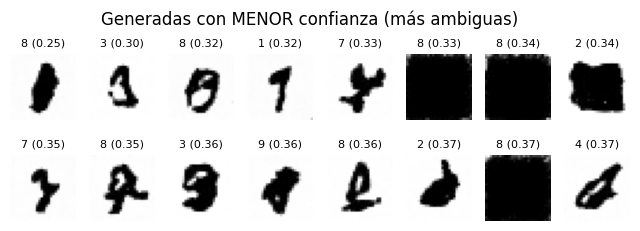

In [28]:
conf_gen = p_gen.max(1)
best = np.argsort(-conf_gen)[:16]
worst = np.argsort(conf_gen)[:16]

plot_multiple_images(X_gen[best], 8, titles=[f"{pred_gen[i]} ({conf_gen[i]:.2f})" for i in best])
plt.suptitle("Generadas con MAYOR confianza", y=1.03); plt.show()

plot_multiple_images(X_gen[worst], 8, titles=[f"{pred_gen[i]} ({conf_gen[i]:.2f})" for i in worst])
plt.suptitle("Generadas con MENOR confianza (más ambiguas)", y=1.03); plt.show()

### 6.5 ¿El modelo memoriza? Vecino más cercano en el conjunto de entrenamiento
Un buen generador produce dígitos *nuevos*, no copias. Para algunas imágenes generadas buscamos la imagen de entrenamiento más parecida en el espacio de características; si fueran idénticas, el modelo estaría memorizando.

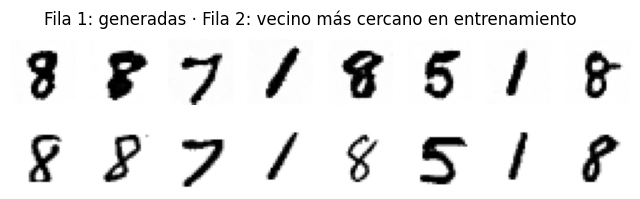

In [29]:
sub_idx = np.random.default_rng(1).choice(len(X_train), min(20000, len(X_train)), replace=False)
f_bank = feature_extractor.predict(to_pm1(X_train[sub_idx]), batch_size=1000, verbose=0)
query = best[:8]
d = ((f_gen[query][:, None, :] - f_bank[None]) ** 2).sum(-1)
nn = sub_idx[d.argmin(1)]

pairs = np.concatenate([X_gen[query], to_pm1(X_train[nn])])
plot_multiple_images(pairs, 8)
plt.suptitle("Fila 1: generadas · Fila 2: vecino más cercano en entrenamiento", y=1.02)
plt.show()

### 6.6 Cómo interpretar los resultados

- **FID y KID** deben quedar mucho más cerca de la línea base “real vs real” que de la del ruido. La línea base real no es cero porque son dos muestras distintas de la misma distribución; es el mejor valor que podemos esperar con este $N$.
- **Classifier Score** cercano a 10 indica dígitos nítidos (cada uno se reconoce sin duda) y diversos (aparecen las 10 clases por igual). Las imágenes reales dan ≈ 9.8–9.9.
- **Entropía de clases** cerca de 2.30 y un histograma plano confirman que no hay *mode collapse*.
- La sección de vecinos más cercanos permite argumentar que el modelo **genera** y no copia.

Comparado con Fashion MNIST, MNIST suele dar resultados visualmente mejores con este mismo modelo pequeño: los dígitos son trazos simples sobre fondo negro, con mucha menos textura que la ropa. Los errores típicos son trazos “a medio camino” entre dos dígitos (4/9, 3/5, 7/1), justamente los que aparecen en la fila de menor confianza.

> 📝 Después de correr el notebook, reemplaza este párrafo con tus números reales y una o dos frases de análisis.

In [30]:
# Guardamos el modelo entrenado (pesos) y una muestra de las imágenes generadas
model.save_weights("mnist_diffusion_final.weights.h5")
np.save("mnist_generated_samples.npy", X_gen[:256])
results.to_csv("mnist_metricas.csv")
print("Archivos guardados: mnist_diffusion_final.weights.h5, mnist_generated_samples.npy, mnist_metricas.csv")

Archivos guardados: mnist_diffusion_final.weights.h5, mnist_generated_samples.npy, mnist_metricas.csv
